# Chapter 3: Slope

Checks the slope sandwich of [chapter 3](../../book/03-slope.md):

```
vertical_error / sqrt(1 + slope_limit^2)  <=  nearest_distance  <=  vertical_error
```

on straight lines, where the left side is an equality, and on random sine models of 1, 3, 10
and 30 terms, where the slope limit is the sum of frequency times the size of the amplitude.
Then the three "check yourself" answers. These are measurements. The Lean proof
(`Sandwich.lean`) is the proof.

Run every cell, top to bottom. A failed check stops the notebook.

In [1]:
from common import *

use_style()

SLACK = 3e-4          # the nearest distance is measured on a polyline, not on the exact curve
generator = torch.Generator().manual_seed(3)

## Straight lines: the left side is exact

A line of slope `m` has slope limit `m`, and the nearest distance to it is exactly
`vertical_error / sqrt(1 + m^2)`. The chapter says a straight line is the case where the left
side is as tight as it can be.

In [2]:
largest_line_gap = 0.0

for slope in (0.0, 0.5, 1.0, 3.0, 10.0):
    line = lambda inputs, slope=slope: slope * inputs
    for point_x, point_y in torch.rand(2, 20, generator=generator).T * 4 - 2:
        vertical_error = get_vertical_error(line(point_x), point_y)
        nearest_distance = get_nearest_distance(line, point_x, point_y, slope, resolution=1e-4)
        lower_bound = vertical_error / math.sqrt(1 + slope ** 2)
        largest_line_gap = max(largest_line_gap, abs(nearest_distance - lower_bound))

report("straight lines meet the lower bound exactly", largest_line_gap < 1e-9,
       f"largest gap {largest_line_gap:.1e}")

[PASS] straight lines meet the lower bound exactly  (largest gap 4.4e-16)


True

## Random sine models: both sides of the sandwich

Four model sizes, three random models of each, and 60 random data points for each model:
720 trials on 12 models. The nearest distance is measured with `include_foot=False`, so the
upper side is a real test: the point straight above or below the data point is not a sample. For every trial the notebook keeps the slope limit, the vertical error, the nearest
distance and the lower bound, so the figure at the end is drawn from exactly these points.

In [3]:
trials = []

for num_terms in (1, 3, 10, 30):
    for _ in range(3):
        model = SineModel(num_terms, amplitude_scale=1.0, generator=generator)
        slope_limit = model.get_slope_limit()
        for point_x, point_y in torch.rand(2, 60, generator=generator).T * 2 - 1:
            vertical_error = get_vertical_error(model(point_x.reshape(1)), point_y)
            nearest_distance = get_nearest_distance(model, point_x, point_y, slope_limit, resolution=2e-3,
                                                    include_foot=False)
            lower_bound = vertical_error / math.sqrt(1 + slope_limit ** 2)
            trials.append({"num_terms": num_terms, "slope_limit": slope_limit,
                           "vertical_error": vertical_error, "nearest_distance": nearest_distance,
                           "lower_bound": lower_bound})

smallest_lower_slack = min(trial["nearest_distance"] - trial["lower_bound"] for trial in trials)
smallest_upper_slack = min(trial["vertical_error"] - trial["nearest_distance"] for trial in trials)

report("lower bound holds for every trial", smallest_lower_slack >= -SLACK,
       f"{len(trials)} trials, smallest nearest - lower = {smallest_lower_slack:.2e}")
report("upper bound holds for every trial", smallest_upper_slack >= -SLACK,
       f"smallest vertical - nearest = {smallest_upper_slack:.2e}")

[PASS] lower bound holds for every trial  (720 trials, smallest nearest - lower = 5.12e-05)
[PASS] upper bound holds for every trial  (smallest vertical - nearest = 3.21e-05)


True

## Check yourself

The three questions at the end of the chapter, answered by measuring a line of the right slope with
`get_nearest_distance`.

1. A model has slope limit 0. The sandwich says the two distances are equal.
2. A model has slope at most 1 and vertical error 1. The curve can pass no closer than `1 / sqrt(2)`, about 0.71.
3. The vertical error is 0.5 and the nearest distance is 0.005. Then `sqrt(1 + slope_limit^2)` is at least 100, so the slope reaches at least 99.99.


In [4]:
flat_line = lambda inputs: 0.0 * inputs
flat_vertical = get_vertical_error(flat_line(torch.tensor(0.7)), 1.0)
flat_nearest = get_nearest_distance(flat_line, 0.7, 1.0, 0.0, include_foot=False)
report("slope limit 0: the two distances are equal", abs(flat_nearest - flat_vertical) < 1e-9,
       f"vertical {flat_vertical:.4f}, nearest {flat_nearest:.4f}")

slope_one_line = lambda inputs: inputs
slope_one_nearest = get_nearest_distance(slope_one_line, 0.0, 1.0, 1.0, resolution=1e-4, include_foot=False)
report("slope 1, vertical error 1: the nearest distance is 1 / sqrt(2) = 0.7071 (the closest it can be)",
       abs(slope_one_nearest - 1 / math.sqrt(2)) < 1e-6, f"measured {slope_one_nearest:.5f}")

steep_slope = 99.995
steep_line = lambda inputs: steep_slope * inputs
steep_nearest = get_nearest_distance(steep_line, 0.0, 0.5, steep_slope, resolution=1e-4, include_foot=False)
report("vertical 0.5, nearest 0.005: a line of slope 99.995 does it, so the slope reaches at least 99.99",
       abs(steep_nearest - 0.005) < 1e-6, f"measured nearest {steep_nearest:.6f}")


[PASS] slope limit 0: the two distances are equal  (vertical 1.0000, nearest 1.0000)
[PASS] slope 1, vertical error 1: the nearest distance is 1 / sqrt(2) = 0.7071 (the closest it can be)  (measured 0.70711)
[PASS] vertical 0.5, nearest 0.005: a line of slope 99.995 does it, so the slope reaches at least 99.99  (measured nearest 0.005000)


True

## Figure for the chapter

Left: a curve with slope at most the slope limit stays inside a wedge, so the nearest point
cannot be closer than the wedge allows. Right: the 720 measured points of nearest distance over
vertical error, all between the lower bound and 1. Written to `book/figures/03-slope-sandwich.png`.

wrote book/figures/03-slope-sandwich.png


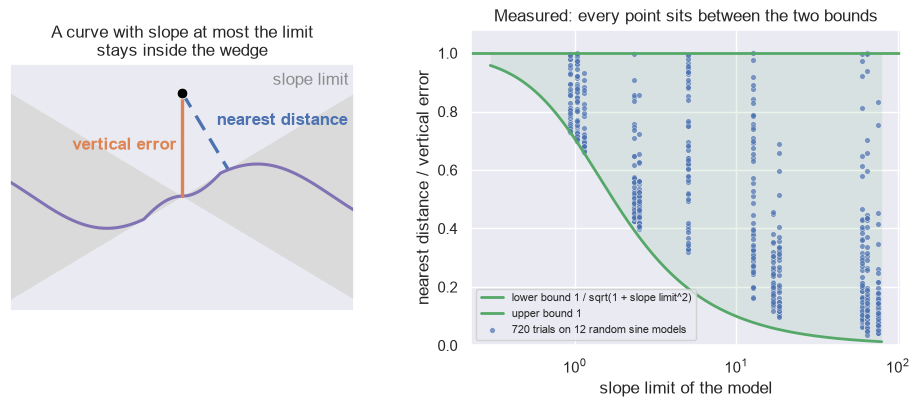

In [5]:
figure, (left, right) = plt.subplots(1, 2, figsize=(11.5, 4.1), gridspec_kw={"width_ratios": [1, 1.25]})

# Left: the wedge. The nearest point of the wedge's edge to the data point bounds the curve's.
wedge_slope = 0.6
height_of_data = 0.9
wedge_x = np.linspace(-1.5, 1.5, 301)
left.fill_between(wedge_x, -wedge_slope * np.abs(wedge_x), wedge_slope * np.abs(wedge_x), color=GRID, alpha=0.9, linewidth=0)
curve_x = np.linspace(-1.5, 1.5, 400)
curve_y = 0.28 * np.sin(2.4 * curve_x) * np.minimum(1, np.abs(curve_x) * 3)
sns.lineplot(x=curve_x, y=curve_y, color=MODEL, linewidth=2.2, ax=left)
left.plot([0, 0], [0, height_of_data], color=VERTICAL, linewidth=2.4)
edge_direction = np.array([1, wedge_slope]) / math.sqrt(1 + wedge_slope ** 2)
foot = edge_direction * (np.array([0.0, height_of_data]) @ edge_direction)
left.plot([0, foot[0]], [height_of_data, foot[1]], color=NEAREST, linewidth=2.4, linestyle=(0, (5, 3)))
sns.scatterplot(x=[0], y=[height_of_data], color=DATA, s=60, zorder=5, ax=left, legend=False)
left.text(-0.05, height_of_data * 0.45, "vertical error", color=VERTICAL, ha="right", fontweight="bold")
left.text(0.30, 0.62, "nearest distance", color=NEAREST, fontweight="bold")
left.text(1.45, 0.97, "slope limit", color=MUTED, ha="right")
left.set(aspect="equal", xlim=(-1.5, 1.5), ylim=(-1.0, 1.15), xticks=[], yticks=[],
         title="A curve with slope at most the limit\nstays inside the wedge")

# Right: every measured trial lies between the two bounds.
slopes = np.array([trial["slope_limit"] for trial in trials])
ratios = np.array([trial["nearest_distance"] / trial["vertical_error"] for trial in trials])
slope_grid = np.geomspace(min(slopes.min(), 0.3), slopes.max() * 1.05, 300)
right.fill_between(slope_grid, 1 / np.sqrt(1 + slope_grid ** 2), 1, color=BOUND, alpha=0.12, linewidth=0)
sns.lineplot(x=slope_grid, y=1 / np.sqrt(1 + slope_grid ** 2), color=BOUND, linewidth=2,
             label="lower bound 1 / sqrt(1 + slope limit^2)", ax=right)
right.axhline(1, color=BOUND, linewidth=2, label="upper bound 1")
sns.scatterplot(x=slopes, y=ratios, s=16, color=NEAREST, alpha=0.7,
                label=f"{len(trials)} trials on 12 random sine models", ax=right)
right.set(xscale="log", ylim=(0, 1.08), xlabel="slope limit of the model",
          ylabel="nearest distance / vertical error", title="Measured: every point sits between the two bounds")
right.legend(loc="lower left", fontsize=8)

figure.subplots_adjust(wspace=0.3)
save_figure(figure, "03-slope-sandwich")